In [16]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

In [17]:

CANDIDATE_PATHS = [
    Path("../Data/Original/train.csv"),
    Path("Data/Original/train.csv"),
    Path("../Data/Original/train.csv")
]
TRAIN_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)
if TRAIN_PATH is None:
    raise FileNotFoundError("Place train.csv in Data/Original or update TRAIN_PATH.")

df = pd.read_csv(TRAIN_PATH)
print("Training data loaded successfully.")

Training data loaded successfully.


In [18]:
display(df.head())

,id,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,0,15674932,Okwudilichukwu,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0
1,1,15749177,Okwudiliolisa,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0
2,2,15694510,Hsueh,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0
3,3,15741417,Kao,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0
4,4,15766172,Chiemenam,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0


In [19]:
rows, columns = df.shape
print(f"Rows: {rows:,}")
print(f"Columns: {columns}")

Rows: 165,034
Columns: 14


In [20]:
print(df.columns.tolist())

['id', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 165034 entries, 0 to 165033
Data columns (total 14 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   id               165034 non-null  int64  
 1   CustomerId       165034 non-null  int64  
 2   Surname          165034 non-null  str    
 3   CreditScore      165034 non-null  int64  
 4   Geography        165034 non-null  str    
 5   Gender           165034 non-null  str    
 6   Age              165034 non-null  float64
 7   Tenure           165034 non-null  int64  
 8   Balance          165034 non-null  float64
 9   NumOfProducts    165034 non-null  int64  
 10  HasCrCard        165034 non-null  float64
 11  IsActiveMember   165034 non-null  float64
 12  EstimatedSalary  165034 non-null  float64
 13  Exited           165034 non-null  int64  
dtypes: float64(5), int64(6), str(3)
memory usage: 17.6 MB


In [22]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
id,165034.0,8.251650e+04,47641.356500,0.00,41258.25,82516.5,1.237748e+05,165033.00
CustomerId,165034.0,1.569201e+07,71397.816791,15565701.00,15633141.00,15690169.0,1.575682e+07,15815690.00
CreditScore,165034.0,6.564544e+02,80.103340,350.00,597.00,659.0,7.100000e+02,850.00
Age,165034.0,3.812589e+01,8.867205,18.00,32.00,37.0,4.200000e+01,92.00
Tenure,165034.0,5.020353e+00,2.806159,0.00,3.00,5.0,7.000000e+00,10.00
Balance,165034.0,5.547809e+04,62817.663278,0.00,0.00,0.0,1.199395e+05,250898.09
NumOfProducts,165034.0,1.554455e+00,0.547154,1.00,1.00,2.0,2.000000e+00,4.00
HasCrCard,165034.0,7.539537e-01,0.430707,0.00,1.00,1.0,1.000000e+00,1.00
IsActiveMember,165034.0,4.977702e-01,0.499997,0.00,0.00,0.0,1.000000e+00,1.00
EstimatedSalary,165034.0,1.125748e+05,50292.865585,11.58,74637.57,117948.0,1.551525e+05,199992.48


In [23]:
display(df.describe(include="object").T)

,count,unique,top,freq
Surname,165034,2797,Hsia,2456
Geography,165034,3,France,94215
Gender,165034,2,Male,93150


In [24]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include=["object", "category"]).columns.tolist()
print("Numerical columns:", numeric_columns)
print("Categorical columns:", categorical_columns)

Numerical columns: ['id', 'CustomerId', 'CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
Categorical columns: ['Surname', 'Geography', 'Gender']


In [25]:
target = "Exited"
print("Target column exists:", target in df.columns)
print("Target values:", sorted(df[target].dropna().unique()))

Target column exists: True
Target values: [np.int64(0), np.int64(1)]


In [26]:
missing_count = df.isna().sum().sort_values(ascending=False)
missing_percent = (df.isna().mean() * 100).sort_values(ascending=False)
missing_table = pd.DataFrame({"Missing Count": missing_count, "Missing Percent": missing_percent})
display(missing_table)

,Missing Count,Missing Percent
id,0,0.0
CustomerId,0,0.0
Surname,0,0.0
CreditScore,0,0.0
Geography,0,0.0
Gender,0,0.0
Age,0,0.0
Tenure,0,0.0
Balance,0,0.0
NumOfProducts,0,0.0


In [28]:
import matplotlib.pyplot as plt

missing_count = df.isnull().sum()

if missing_count.sum() > 0:

    missing_count[missing_count > 0].plot(

        kind="bar",

        figsize=(10, 4),

        title="Missing Values by Column"

    )

    plt.ylabel("Number of missing values")

    plt.xlabel("Column")

    plt.tight_layout()

    plt.show()

else:

    print("No missing values found in the dataset.")

No missing values found in the dataset.


In [29]:
duplicate_rows = df.duplicated().sum()
print(f"Exact duplicate rows: {duplicate_rows:,}")

Exact duplicate rows: 0


In [30]:
if "CustomerId" in df.columns:
    print("Repeated CustomerId rows:", df["CustomerId"].duplicated().sum())
    print("Unique CustomerId values:", df["CustomerId"].nunique())

Repeated CustomerId rows: 141813
Unique CustomerId values: 23221


In [31]:
unique_counts = df.nunique(dropna=False).sort_values()
display(unique_counts.to_frame("Unique Values"))

,Unique Values
Gender,2
Exited,2
HasCrCard,2
IsActiveMember,2
Geography,3
NumOfProducts,4
Tenure,11
Age,71
CreditScore,457
Surname,2797


In [32]:
for col in ["HasCrCard", "IsActiveMember", "Exited"]:
    if col in df.columns:
        print(f"{col}: {sorted(df[col].dropna().unique())}")

HasCrCard: [np.float64(0.0), np.float64(1.0)]
IsActiveMember: [np.float64(0.0), np.float64(1.0)]
Exited: [np.int64(0), np.int64(1)]


In [33]:
range_columns = ["CreditScore", "Age", "Tenure", "NumOfProducts", "Balance", "EstimatedSalary"]
for col in range_columns:
    if col in df.columns:
        print(f"{col}: min={df[col].min()}, max={df[col].max()}")

CreditScore: min=350, max=850
Age: min=18.0, max=92.0
Tenure: min=0, max=10
NumOfProducts: min=1, max=4
Balance: min=0.0, max=250898.09
EstimatedSalary: min=11.58, max=199992.48


In [34]:
for col in ["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary"]:
    if col in df.columns:
        print(f"{col}: negative values = {(df[col] < 0).sum()}")

CreditScore: negative values = 0
Age: negative values = 0
Tenure: negative values = 0
Balance: negative values = 0
EstimatedSalary: negative values = 0


In [35]:
for col in categorical_columns:
    print(f"\n{col}:")
    print(sorted(df[col].dropna().unique().tolist()))


Surname:
['Abazu', 'Abbie', 'Abbott', 'Abdullah', 'Abdulov', 'Abel', 'Abernathy', 'Abramov', 'Abramova', 'Abramovich', 'Abramowitz', 'Abrego', 'Abron', 'Achebe', 'Adams', 'Adamson', 'Afamefula', 'Afamefuna', 'Afanasyev', 'Afanasyeva', 'Agafonova', 'Aguirre', 'Ah Mouy', 'Ahern', 'Ahmed', 'Aiken', 'Aikenhead', 'Ainsworth', 'Aitken', 'Ajuluchukwu', 'Akabueze', 'Akeroyd', 'Akhtar', 'Akobundu', 'Aksakova', 'Aksenov', 'Aksenova', 'Aksyonov', 'Aksyonova', 'Akubundu', 'Akudinobi', 'Alaniz', 'Alderete', 'Aldrich', 'Aldridge', 'Aleksandrova', 'Alekseeva', 'Alekseyeva', 'Aleshire', 'Alexander', 'Alexandrov', 'Alexandrova', 'Alexeeva', 'Alexeieva', 'Alexeyeva', 'Algarin', 'Algeranoff', 'Ali', 'Aliyev', 'Aliyeva', 'Allan', 'Allard', 'Allardyce', 'Allen', 'Alley', 'Alleyne', 'Allingham', 'Allnutt', 'Allsop', 'Alvares', 'Alvarez', 'Amadi', 'Amaechi', 'Amechi', 'Amies', 'Amos', 'Ampt', 'Anayochukwu', 'Anayolisa', 'Andersen', 'Anderson', 'Andreev', 'Andrejew', 'Andrews', 'Andreyev', 'Andreyeva', 'Anen

In [36]:
print("Missing target values:", df[target].isna().sum())
print("Target labels:", df[target].value_counts(dropna=False).to_dict())

Missing target values: 0
Target labels: {0: 130113, 1: 34921}


In [37]:
quality_summary = pd.Series({
    "Rows": len(df),
    "Columns": df.shape[1],
    "Missing cells": int(df.isna().sum().sum()),
    "Exact duplicate rows": int(df.duplicated().sum()),
    "Missing target values": int(df[target].isna().sum())
})
display(quality_summary.to_frame("Result"))

,Result
Rows,165034
Columns,14
Missing cells,0
Exact duplicate rows,0
Missing target values,0


In [38]:
target_counts = df[target].value_counts().sort_index()
display(target_counts.to_frame("Customer Count"))

,Customer Count
Exited,
0,130113
1,34921


In [39]:
target_percent = df[target].value_counts(normalize=True).sort_index() * 100
display(target_percent.to_frame("Percentage"))

,Percentage
Exited,
0,78.840118
1,21.159882


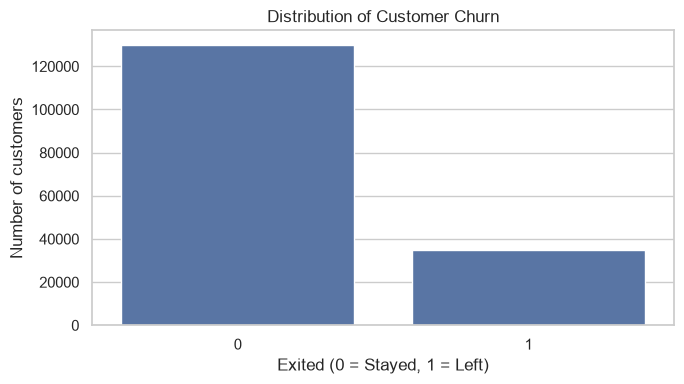

In [40]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x=target)
plt.title("Distribution of Customer Churn")
plt.xlabel("Exited (0 = Stayed, 1 = Left)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

In [41]:
class_share = df[target].value_counts(normalize=True).sort_index() * 100
print(f"Stayed (0): {class_share.get(0, 0):.2f}%")
print(f"Exited (1): {class_share.get(1, 0):.2f}%")

Stayed (0): 78.84%
Exited (1): 21.16%


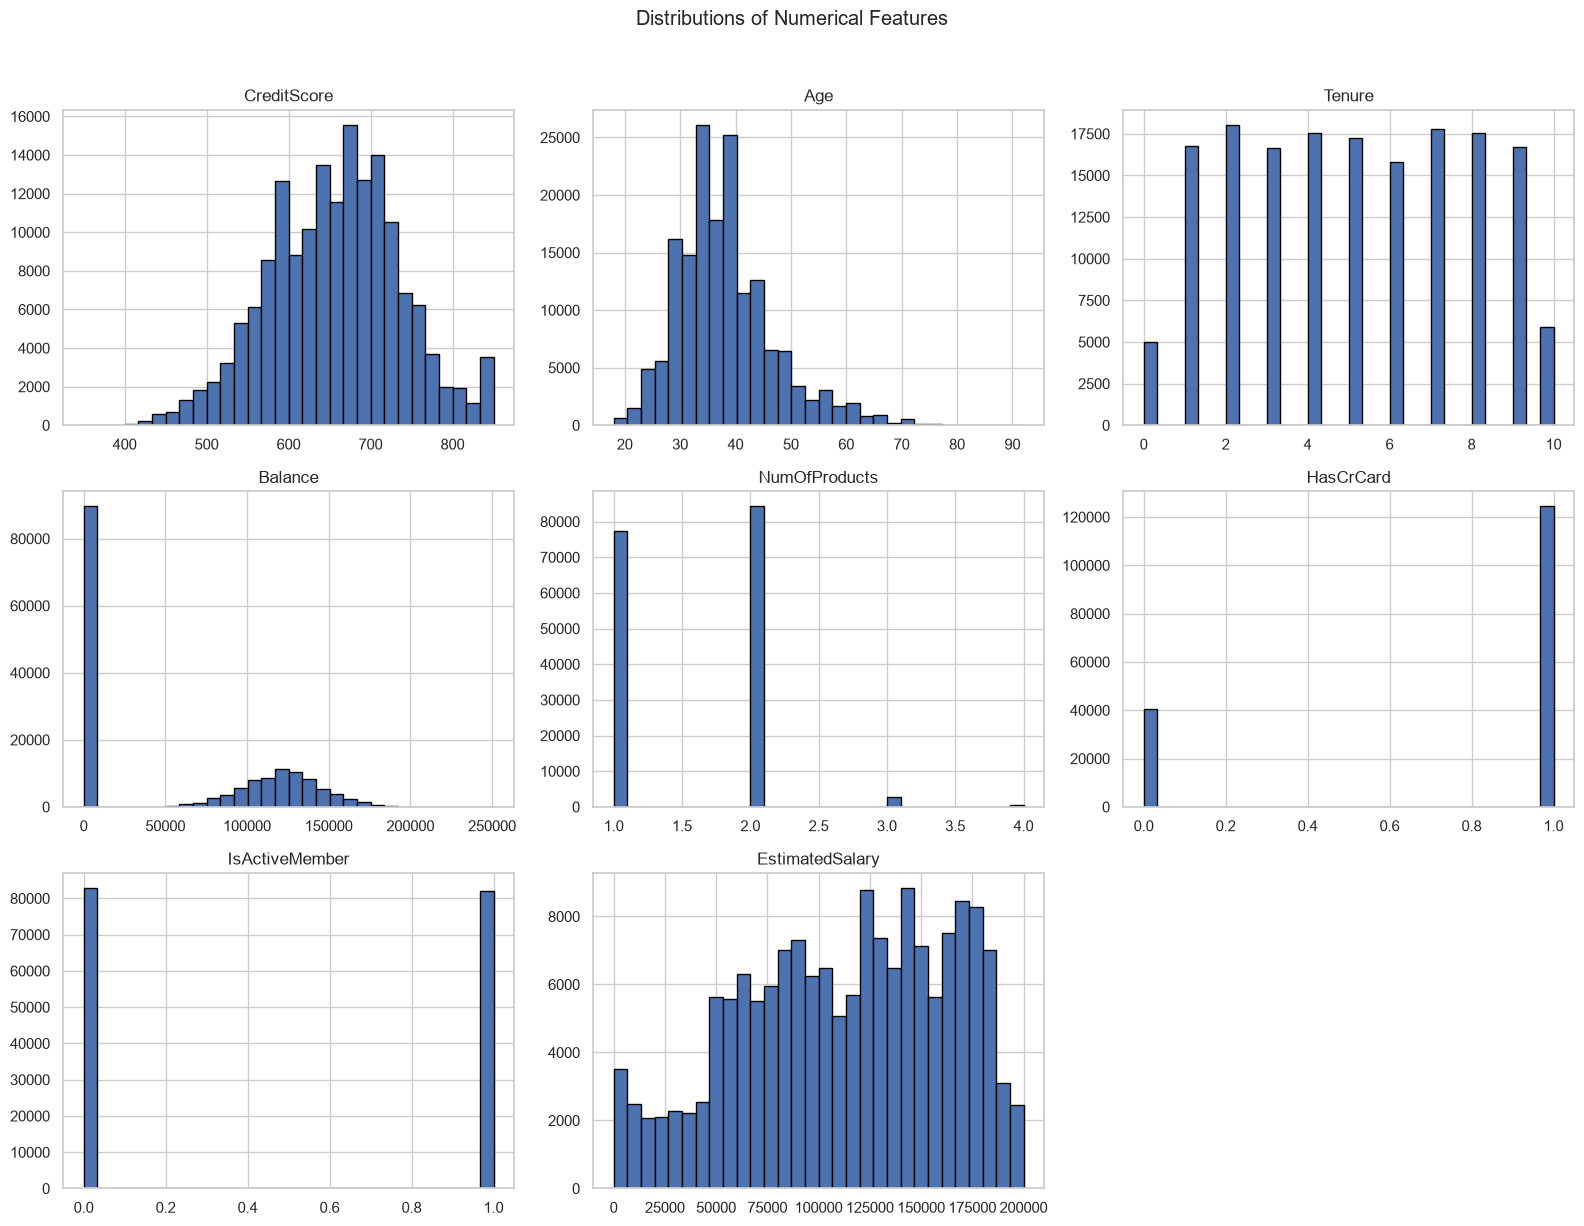

In [42]:
plot_numeric = [c for c in numeric_columns if c not in ["id", "CustomerId", target]]
df[plot_numeric].hist(figsize=(16, 12), bins=30, edgecolor="black")
plt.suptitle("Distributions of Numerical Features", y=1.02)
plt.tight_layout()
plt.show()

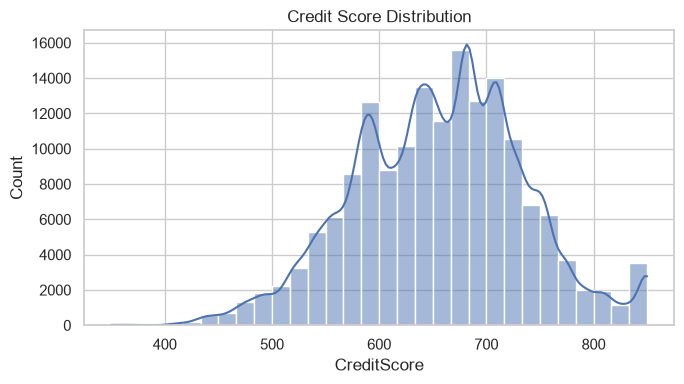

In [43]:
plt.figure(figsize=(7, 4))
sns.histplot(df["CreditScore"], bins=30, kde=True)
plt.title("Credit Score Distribution")
plt.tight_layout()
plt.show()

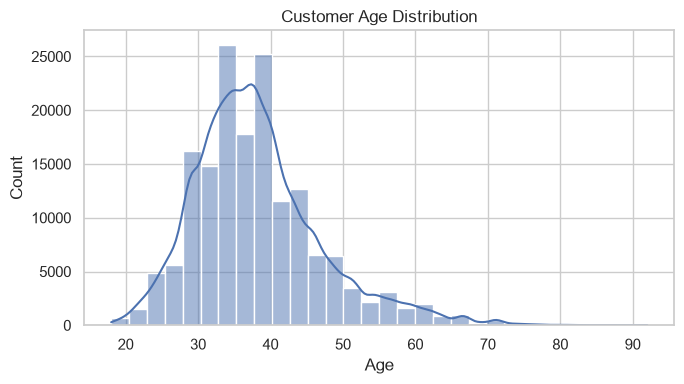

In [44]:
plt.figure(figsize=(7, 4))
sns.histplot(df["Age"], bins=30, kde=True)
plt.title("Customer Age Distribution")
plt.tight_layout()
plt.show()

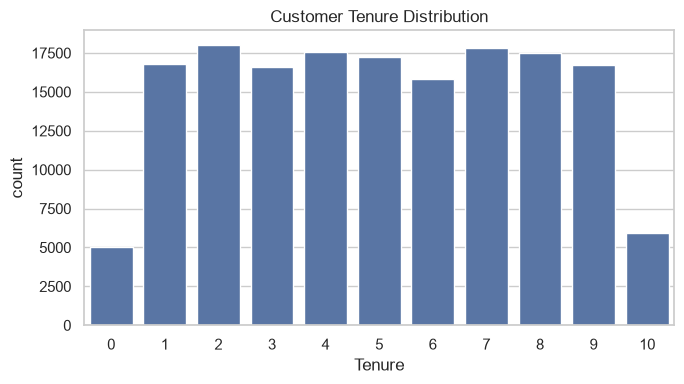

In [45]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Tenure")
plt.title("Customer Tenure Distribution")
plt.tight_layout()
plt.show()

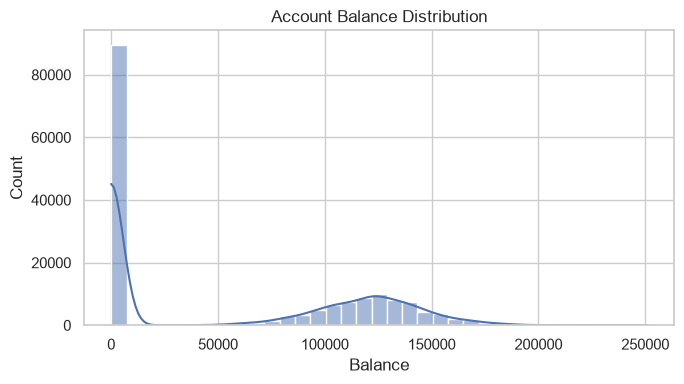

In [46]:
plt.figure(figsize=(7, 4))
sns.histplot(df["Balance"], bins=35, kde=True)
plt.title("Account Balance Distribution")
plt.tight_layout()
plt.show()

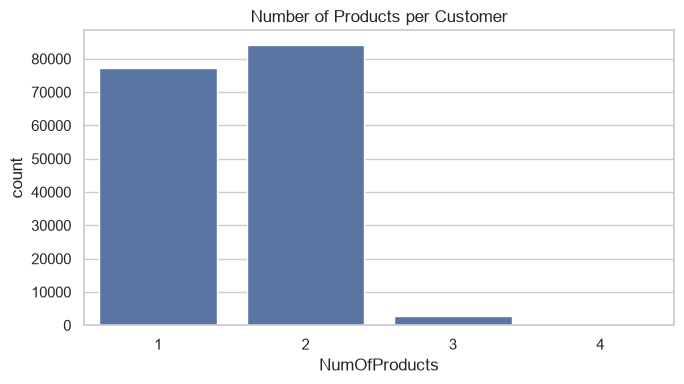

In [47]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="NumOfProducts")
plt.title("Number of Products per Customer")
plt.tight_layout()
plt.show()

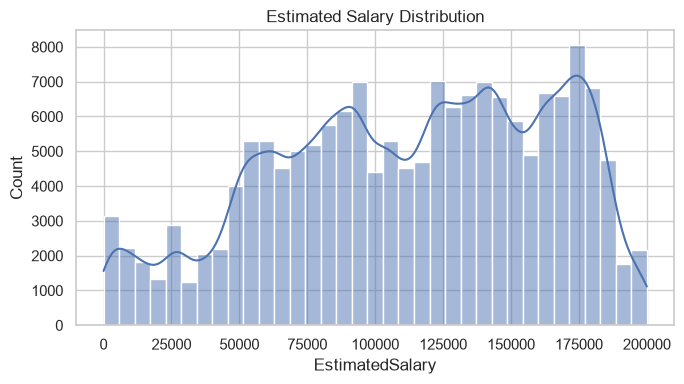

In [48]:
plt.figure(figsize=(7, 4))
sns.histplot(df["EstimatedSalary"], bins=35, kde=True)
plt.title("Estimated Salary Distribution")
plt.tight_layout()
plt.show()

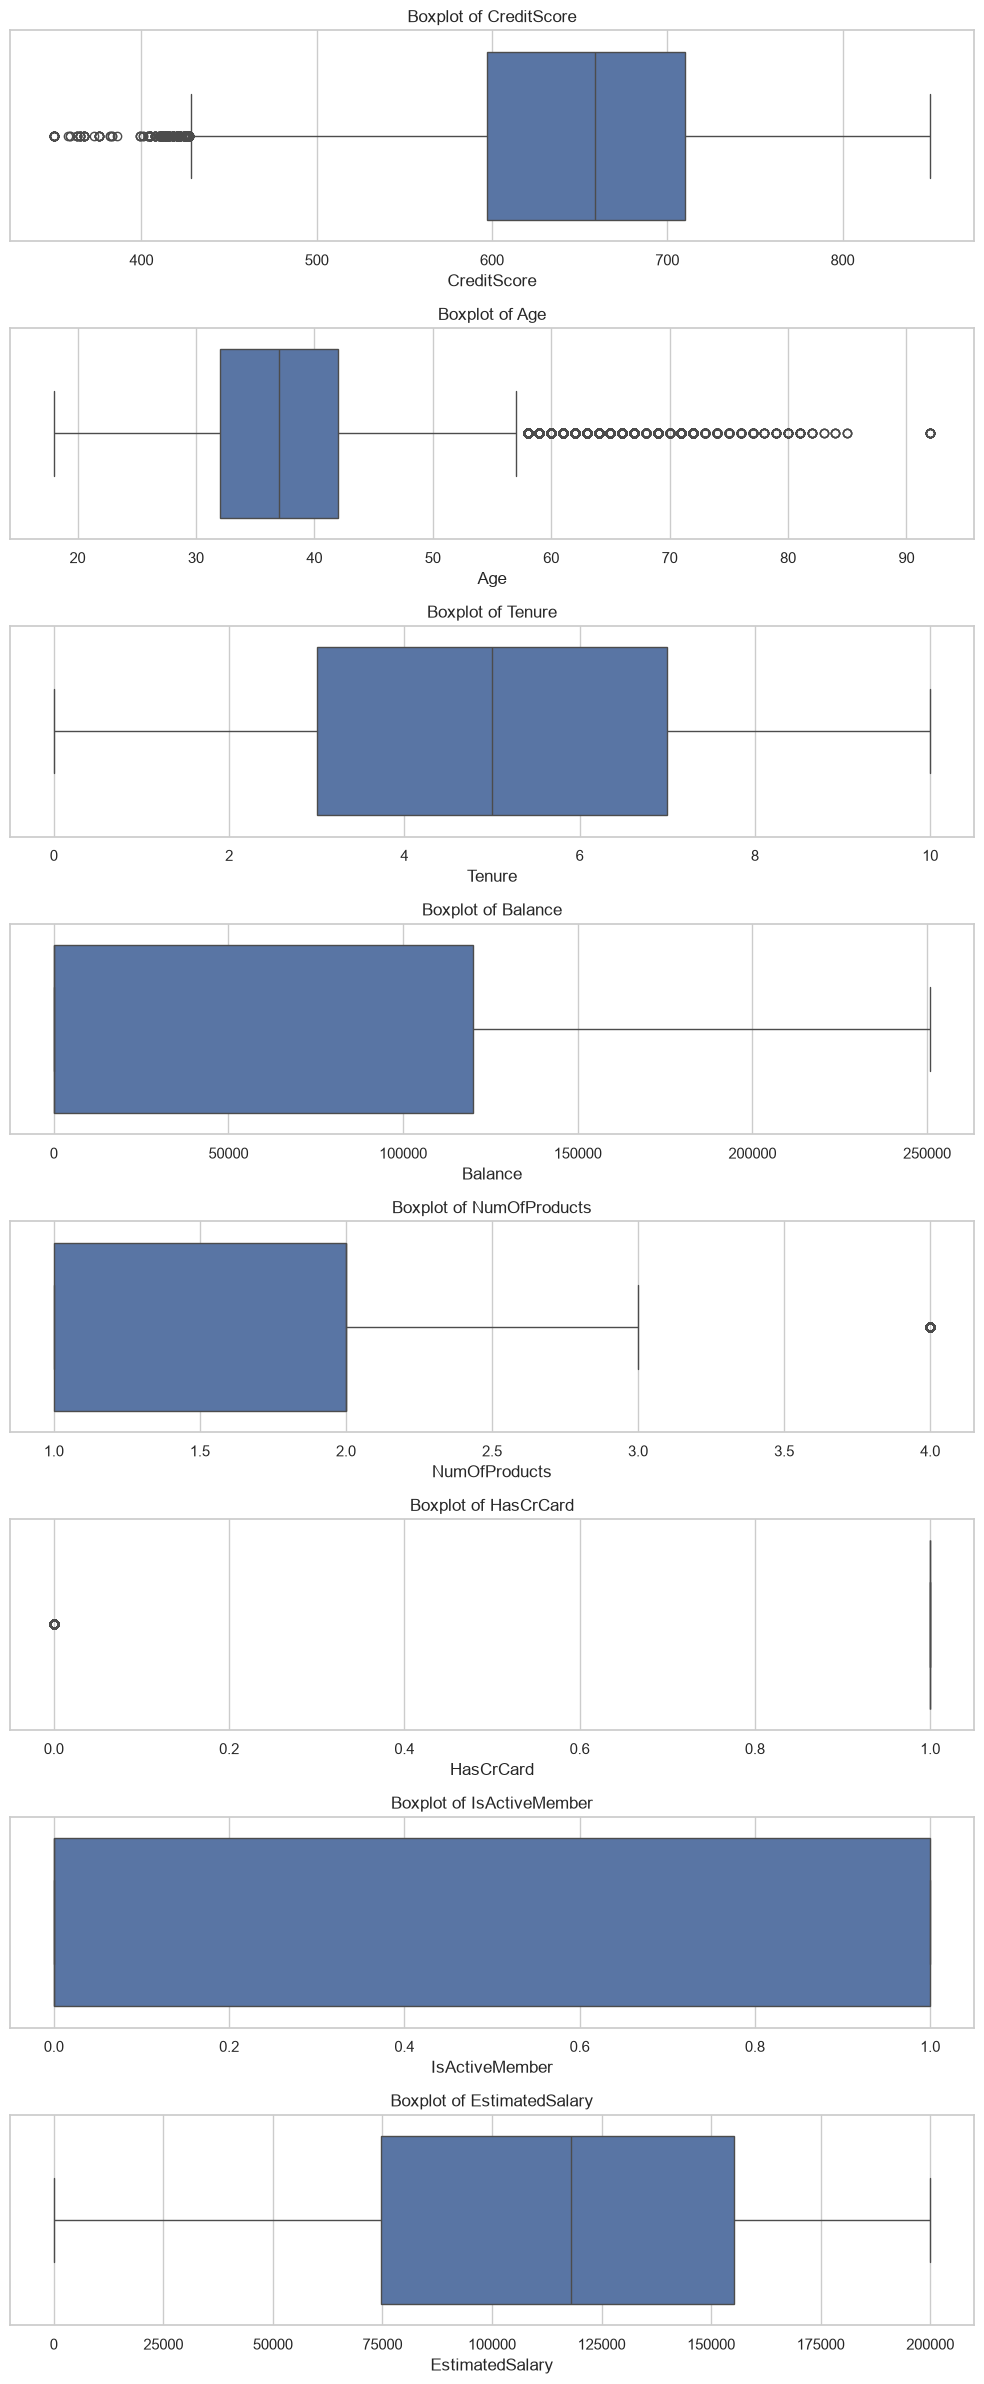

In [49]:
fig, axes = plt.subplots(len(plot_numeric), 1, figsize=(10, 3 * len(plot_numeric)))
for ax, col in zip(np.atleast_1d(axes), plot_numeric):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.show()

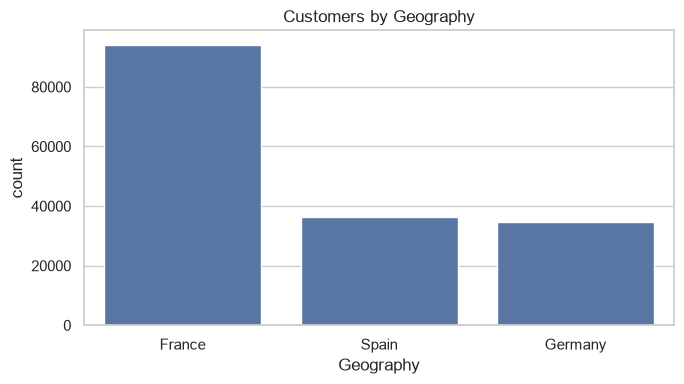

In [50]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Geography", order=df["Geography"].value_counts().index)
plt.title("Customers by Geography")
plt.tight_layout()
plt.show()

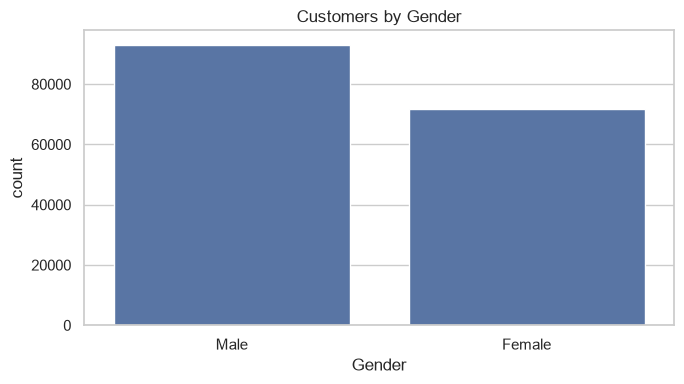

In [51]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Gender")
plt.title("Customers by Gender")
plt.tight_layout()
plt.show()

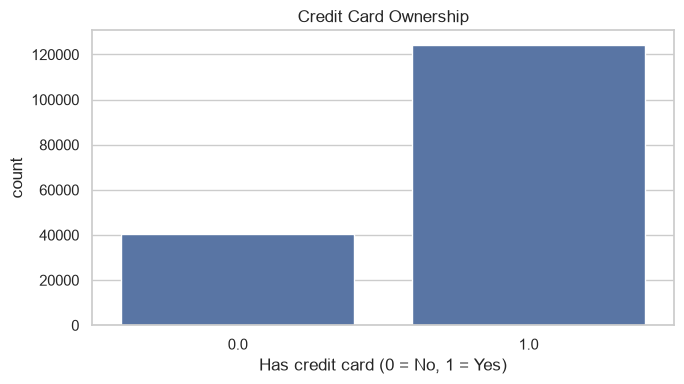

In [52]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="HasCrCard")
plt.title("Credit Card Ownership")
plt.xlabel("Has credit card (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()

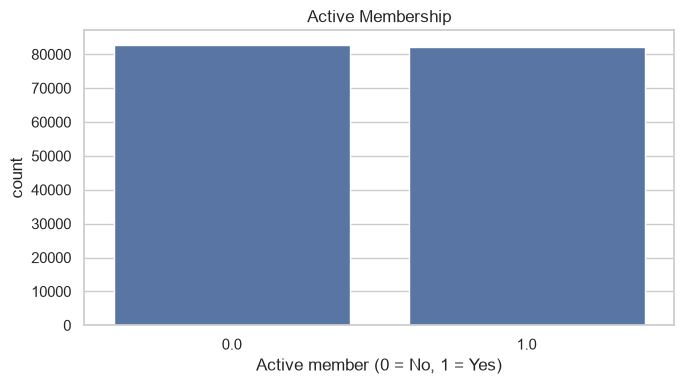

In [53]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="IsActiveMember")
plt.title("Active Membership")
plt.xlabel("Active member (0 = No, 1 = Yes)")
plt.tight_layout()
plt.show()

In [54]:
for col in categorical_columns:
    print(f"\n{col}")
    display(df[col].value_counts(dropna=False).to_frame("Count"))


Surname


,Count
Surname,
Hsia,2456
T'ien,2282
Hs?,1611
Kao,1577
Maclean,1577
...,...
Christmas,1
Ah Mouy,1
Aliyev,1



Geography


,Count
Geography,
France,94215
Spain,36213
Germany,34606



Gender


,Count
Gender,
Male,93150
Female,71884


In [55]:
skewness = df[plot_numeric].skew().sort_values(ascending=False)
display(skewness.to_frame("Skewness"))

,Skewness
Age,0.968063
Balance,0.382020
NumOfProducts,0.368278
IsActiveMember,0.008920
Tenure,0.006490
CreditScore,-0.059291
EstimatedSalary,-0.309022
HasCrCard,-1.179255


In [56]:
kurtosis = df[plot_numeric].kurtosis().sort_values(ascending=False)
display(kurtosis.to_frame("Kurtosis"))

,Kurtosis
Age,1.532406
CreditScore,-0.067452
NumOfProducts,-0.278059
HasCrCard,-0.609365
EstimatedSalary,-0.838845
Tenure,-1.157921
Balance,-1.600852
IsActiveMember,-1.999945


In [57]:
display(df.groupby(target)[plot_numeric].median().T)

Exited,0,1
CreditScore,662.00,651.00
Age,36.00,44.00
Tenure,5.00,5.00
Balance,0.00,98955.87
NumOfProducts,2.00,1.00
HasCrCard,1.00,1.00
IsActiveMember,1.00,0.00
EstimatedSalary,116977.89,120892.96


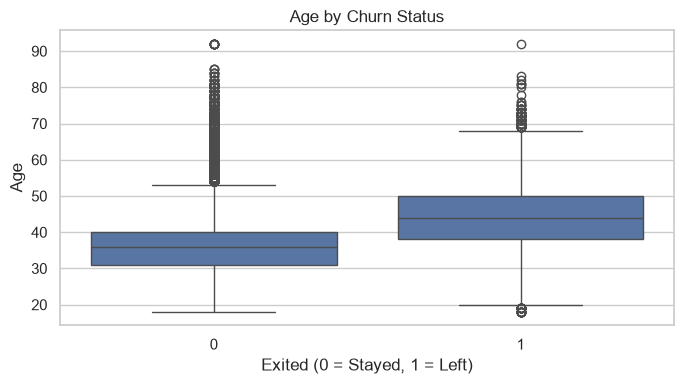

In [58]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x=target, y="Age")
plt.title("Age by Churn Status")
plt.xlabel("Exited (0 = Stayed, 1 = Left)")
plt.tight_layout()
plt.show()

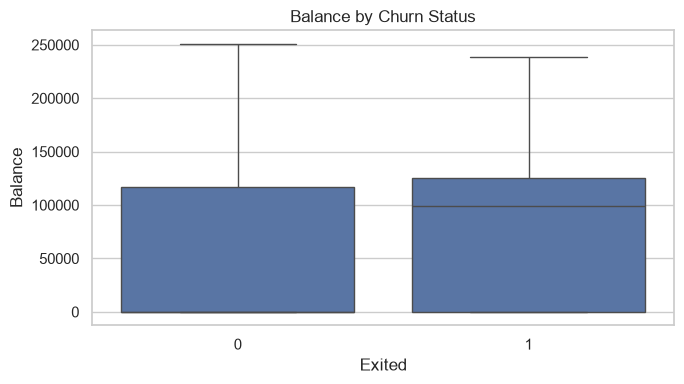

In [59]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x=target, y="Balance")
plt.title("Balance by Churn Status")
plt.tight_layout()
plt.show()

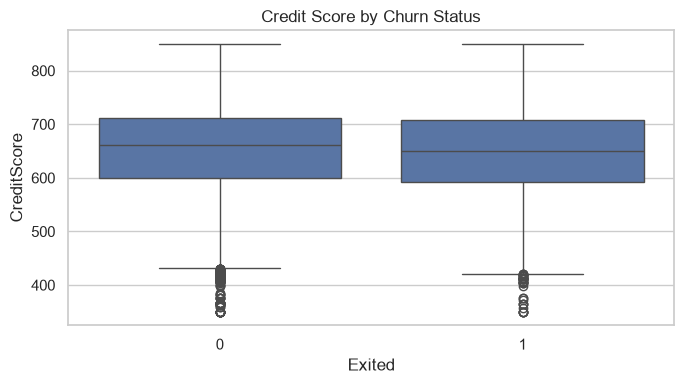

In [60]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x=target, y="CreditScore")
plt.title("Credit Score by Churn Status")
plt.tight_layout()
plt.show()

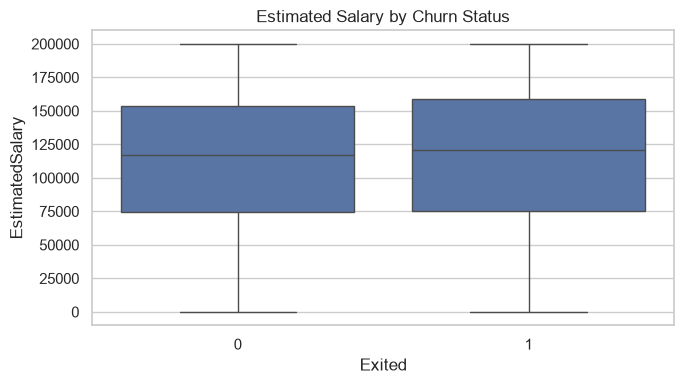

In [61]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x=target, y="EstimatedSalary")
plt.title("Estimated Salary by Churn Status")
plt.tight_layout()
plt.show()

In [62]:
outlier_rows = []
for col in plot_numeric:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_rows.append([col, q1, q3, iqr, lower, upper, int(count)])
outlier_table = pd.DataFrame(outlier_rows, columns=["Feature","Q1","Q3","IQR","Lower Bound","Upper Bound","Outlier Count"])
display(outlier_table)

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,CreditScore,597.00,710.0000,113.0000,427.50000,879.50000,253
1,Age,32.00,42.0000,10.0000,17.00000,57.00000,6394
2,Tenure,3.00,7.0000,4.0000,-3.00000,13.00000,0
3,Balance,0.00,119939.5175,119939.5175,-179909.27625,299848.79375,0
4,NumOfProducts,1.00,2.0000,1.0000,-0.50000,3.50000,475
5,HasCrCard,1.00,1.0000,0.0000,1.00000,1.00000,40606
6,IsActiveMember,0.00,1.0000,1.0000,-1.50000,2.50000,0
7,EstimatedSalary,74637.57,155152.4675,80514.8975,-46134.77625,275924.81375,0


In [63]:
outlier_table["Outlier Percent"] = outlier_table["Outlier Count"] / len(df) * 100
display(outlier_table[["Feature", "Outlier Count", "Outlier Percent"]])

,Feature,Outlier Count,Outlier Percent
0,CreditScore,253,0.153302
1,Age,6394,3.874353
2,Tenure,0,0.000000
3,Balance,0,0.000000
4,NumOfProducts,475,0.287819
5,HasCrCard,40606,24.604627
6,IsActiveMember,0,0.000000
7,EstimatedSalary,0,0.000000


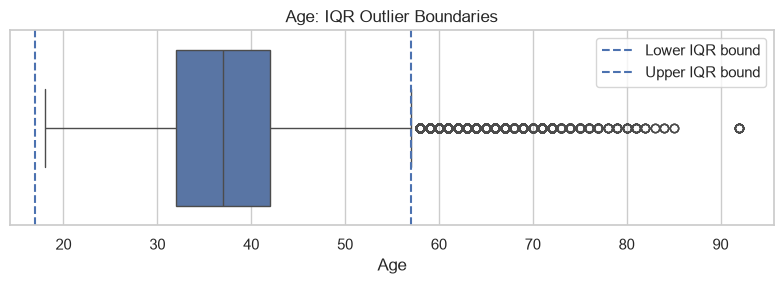

In [64]:
row = outlier_table.set_index("Feature").loc["Age"]
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["Age"])
plt.axvline(row["Lower Bound"], linestyle="--", label="Lower IQR bound")
plt.axvline(row["Upper Bound"], linestyle="--", label="Upper IQR bound")
plt.title("Age: IQR Outlier Boundaries")
plt.legend()
plt.tight_layout()
plt.show()

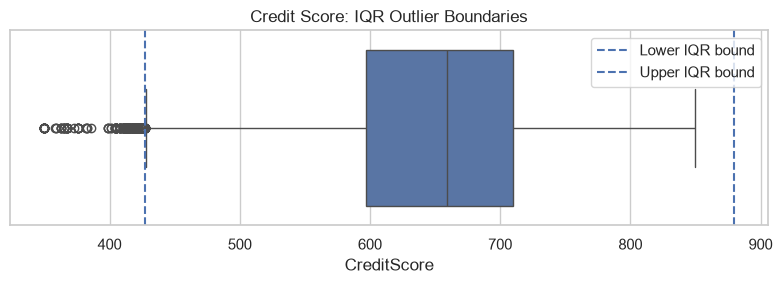

In [65]:
row = outlier_table.set_index("Feature").loc["CreditScore"]
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["CreditScore"])
plt.axvline(row["Lower Bound"], linestyle="--", label="Lower IQR bound")
plt.axvline(row["Upper Bound"], linestyle="--", label="Upper IQR bound")
plt.title("Credit Score: IQR Outlier Boundaries")
plt.legend()
plt.tight_layout()
plt.show()

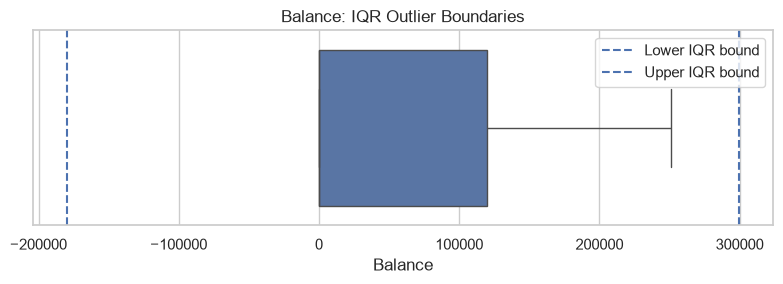

In [66]:
row = outlier_table.set_index("Feature").loc["Balance"]
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["Balance"])
plt.axvline(row["Lower Bound"], linestyle="--", label="Lower IQR bound")
plt.axvline(row["Upper Bound"], linestyle="--", label="Upper IQR bound")
plt.title("Balance: IQR Outlier Boundaries")
plt.legend()
plt.tight_layout()
plt.show()

In [67]:
display(outlier_table[["Feature", "Outlier Count", "Outlier Percent"]])
print("Decision: investigate flagged values; do not automatically remove them.")

,Feature,Outlier Count,Outlier Percent
0,CreditScore,253,0.153302
1,Age,6394,3.874353
2,Tenure,0,0.000000
3,Balance,0,0.000000
4,NumOfProducts,475,0.287819
5,HasCrCard,40606,24.604627
6,IsActiveMember,0,0.000000
7,EstimatedSalary,0,0.000000


Decision: investigate flagged values; do not automatically remove them.


In [68]:
correlation_columns = [c for c in numeric_columns if c not in ["id", "CustomerId"]]
corr = df[correlation_columns].corr(numeric_only=True)
display(corr.round(3))

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
CreditScore,1.000,-0.009,0.001,0.007,0.011,-0.003,0.015,-0.002,-0.027
Age,-0.009,1.000,-0.011,0.064,-0.102,-0.012,0.003,-0.005,0.341
Tenure,0.001,-0.011,1.000,-0.009,0.007,0.005,-0.006,0.001,-0.020
Balance,0.007,0.064,-0.009,1.000,-0.361,-0.019,-0.015,0.009,0.130
NumOfProducts,0.011,-0.102,0.007,-0.361,1.000,0.005,0.040,-0.004,-0.215
HasCrCard,-0.003,-0.012,0.005,-0.019,0.005,1.000,-0.021,0.004,-0.022
IsActiveMember,0.015,0.003,-0.006,-0.015,0.040,-0.021,1.000,-0.008,-0.210
EstimatedSalary,-0.002,-0.005,0.001,0.009,-0.004,0.004,-0.008,1.000,0.019
Exited,-0.027,0.341,-0.020,0.130,-0.215,-0.022,-0.210,0.019,1.000


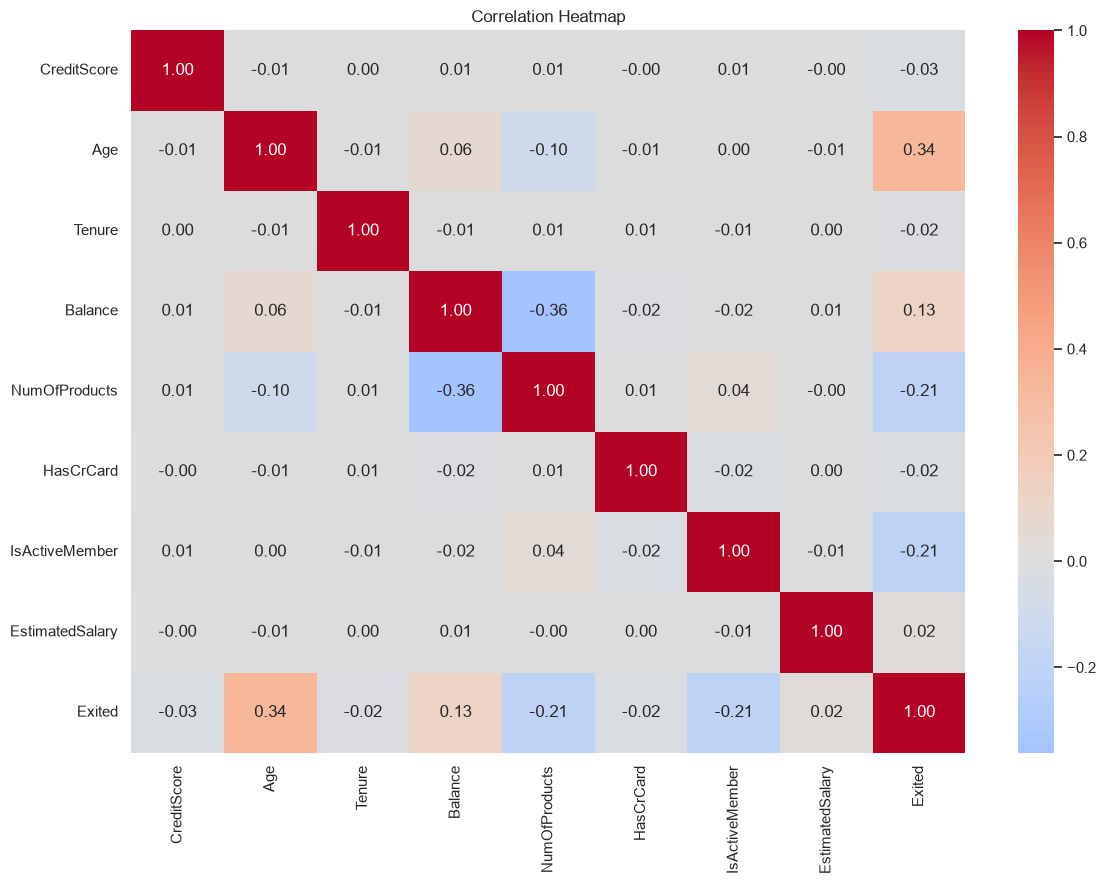

In [69]:
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [70]:
target_corr = corr[target].drop(target).sort_values(key=abs, ascending=False)
display(target_corr.to_frame("Correlation with Exited"))

,Correlation with Exited
Age,0.340768
NumOfProducts,-0.214554
IsActiveMember,-0.210237
Balance,0.129743
CreditScore,-0.027383
HasCrCard,-0.022141
Tenure,-0.019565
EstimatedSalary,0.018827


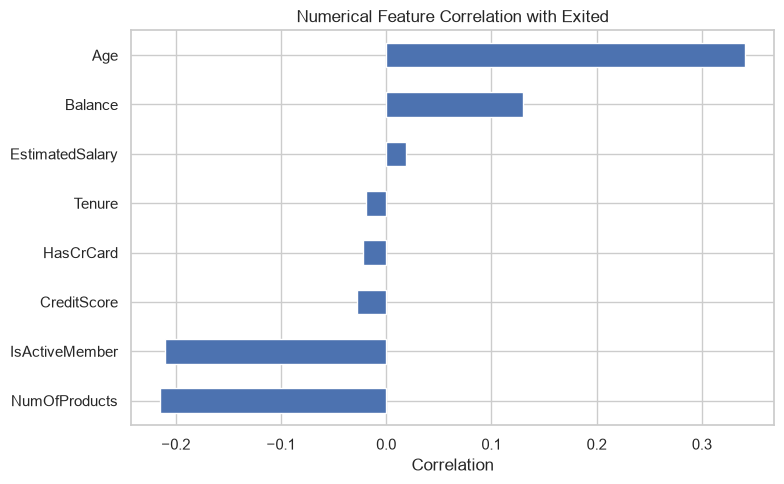

In [71]:
plt.figure(figsize=(8, 5))
target_corr.sort_values().plot(kind="barh")
plt.title("Numerical Feature Correlation with Exited")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

In [72]:
geo_churn = df.groupby("Geography")[target].mean().sort_values(ascending=False) * 100
display(geo_churn.to_frame("Churn Rate (%)"))

,Churn Rate (%)
Geography,
Germany,37.895163
Spain,17.217574
France,16.528154


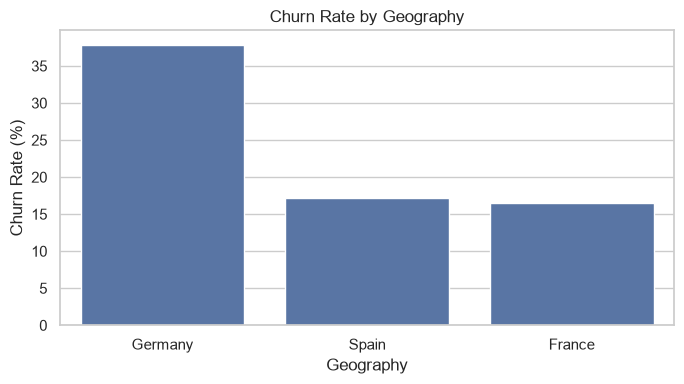

In [73]:
plt.figure(figsize=(7, 4))
sns.barplot(x=geo_churn.index, y=geo_churn.values)
plt.title("Churn Rate by Geography")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

In [74]:
gender_churn = df.groupby("Gender")[target].mean().sort_values(ascending=False) * 100
display(gender_churn.to_frame("Churn Rate (%)"))

,Churn Rate (%)
Gender,
Female,27.968672
Male,15.905529


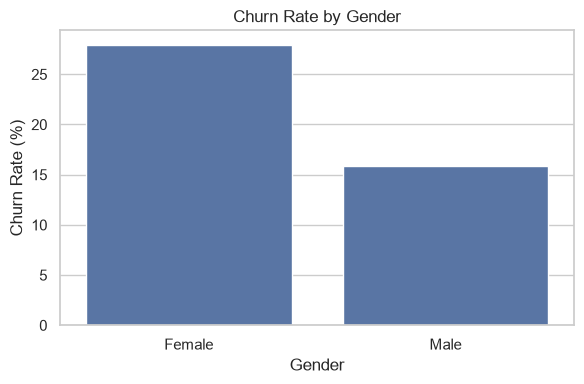

In [75]:
plt.figure(figsize=(6, 4))
sns.barplot(x=gender_churn.index, y=gender_churn.values)
plt.title("Churn Rate by Gender")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

In [76]:
active_churn = df.groupby("IsActiveMember")[target].mean() * 100
display(active_churn.to_frame("Churn Rate (%)"))

,Churn Rate (%)
IsActiveMember,
0.0,29.708632
1.0,12.534541


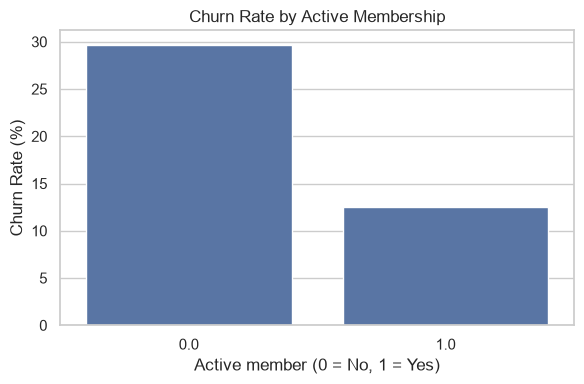

In [77]:
plt.figure(figsize=(6, 4))
sns.barplot(x=active_churn.index.astype(str), y=active_churn.values)
plt.title("Churn Rate by Active Membership")
plt.xlabel("Active member (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

In [78]:
# Keep a copy of the analyzed training data before creating new features.
df_fe = df.copy()
print("Working copy created:", df_fe.shape)

Working copy created: (165034, 14)


In [79]:
age_bins = [0, 25, 40, 55, 120]
age_labels = ["Young", "Adult", "Middle_Aged", "Senior"]
df_fe["Age_Group"] = pd.cut(df_fe["Age"], bins=age_bins, labels=age_labels, right=False)
display(df_fe[["Age", "Age_Group"]].head())

,Age,Age_Group
0,33.0,Adult
1,33.0,Adult
2,40.0,Middle_Aged
3,34.0,Adult
4,33.0,Adult


In [80]:
display(df_fe["Age_Group"].value_counts(dropna=False).to_frame("Customer Count"))

,Customer Count
Age_Group,
Adult,99801
Middle_Aged,50770
Senior,9477
Young,4986


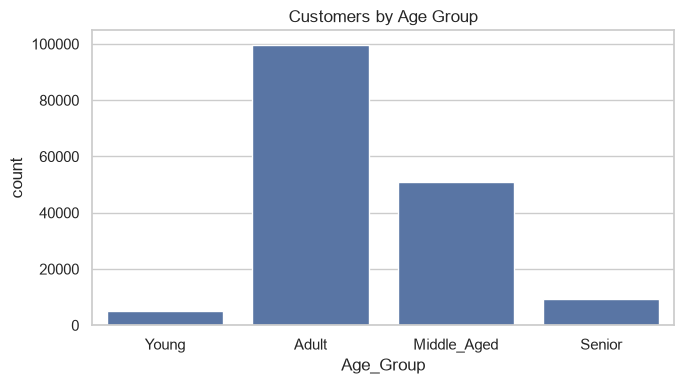

In [81]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df_fe, x="Age_Group", order=age_labels)
plt.title("Customers by Age Group")
plt.tight_layout()
plt.show()

In [82]:
df_fe["HasBalance"] = (df_fe["Balance"] > 0).astype(int)
display(df_fe[["Balance", "HasBalance"]].head())

,Balance,HasBalance
0,0.00,0
1,0.00,0
2,0.00,0
3,148882.54,1
4,0.00,0


In [83]:
display(df_fe["HasBalance"].value_counts().to_frame("Customer Count"))

,Customer Count
HasBalance,
0,89648
1,75386


In [84]:
tenure_bins = [-1, 2, 5, 10]
tenure_labels = ["0-2 years", "3-5 years", "6-10 years"]
df_fe["Tenure_Group"] = pd.cut(df_fe["Tenure"], bins=tenure_bins, labels=tenure_labels)
display(df_fe[["Tenure", "Tenure_Group"]].head())

,Tenure,Tenure_Group
0,3,3-5 years
1,1,0-2 years
2,10,6-10 years
3,2,0-2 years
4,5,3-5 years


In [85]:
display(df_fe["Tenure_Group"].value_counts(dropna=False).to_frame("Customer Count"))

,Customer Count
Tenure_Group,
6-10 years,73770
3-5 years,51452
0-2 years,39812


In [86]:
age_group_churn = df_fe.groupby("Age_Group", observed=False)[target].mean() * 100
display(age_group_churn.to_frame("Churn Rate (%)"))

,Churn Rate (%)
Age_Group,
Young,10.108303
Adult,10.281460
Middle_Aged,38.960016
Senior,46.174950


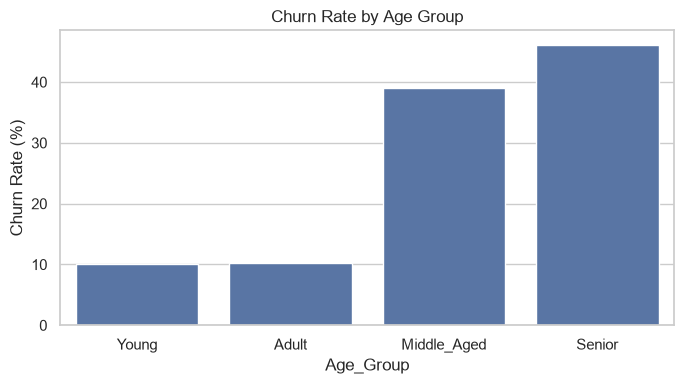

In [87]:
plt.figure(figsize=(7, 4))
sns.barplot(x=age_group_churn.index.astype(str), y=age_group_churn.values)
plt.title("Churn Rate by Age Group")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

In [88]:
tenure_group_churn = df_fe.groupby("Tenure_Group", observed=False)[target].mean() * 100
display(tenure_group_churn.to_frame("Churn Rate (%)"))

,Churn Rate (%)
Tenure_Group,
0-2 years,21.556315
3-5 years,22.514188
6-10 years,20.001356


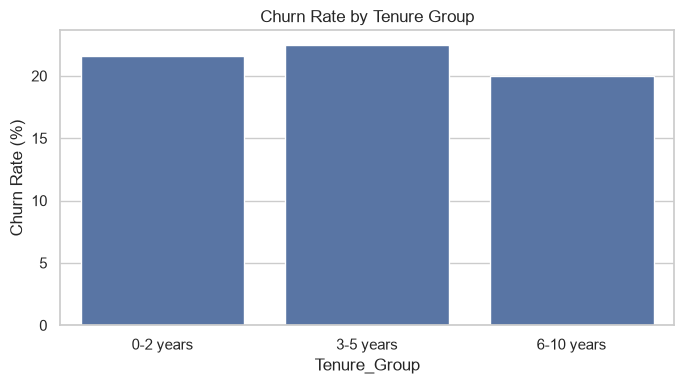

In [89]:
plt.figure(figsize=(7, 4))
sns.barplot(x=tenure_group_churn.index.astype(str), y=tenure_group_churn.values)
plt.title("Churn Rate by Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

In [90]:
identifier_columns = [c for c in ["id", "CustomerId", "Surname"] if c in df_fe.columns]
print("Identifier columns:", identifier_columns)

Identifier columns: ['id', 'CustomerId', 'Surname']


In [91]:
df_model_ready = df_fe.drop(columns=identifier_columns, errors="ignore").copy()
print("Model-oriented dataset shape:", df_model_ready.shape)
display(df_model_ready.head())

Model-oriented dataset shape: (165034, 14)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Age_Group,HasBalance,Tenure_Group
0,668,France,Male,33.0,3,0.00,2,1.0,0.0,181449.97,0,Adult,0,3-5 years
1,627,France,Male,33.0,1,0.00,2,1.0,1.0,49503.50,0,Adult,0,0-2 years
2,678,France,Male,40.0,10,0.00,2,1.0,0.0,184866.69,0,Middle_Aged,0,6-10 years
3,581,France,Male,34.0,2,148882.54,1,1.0,1.0,84560.88,0,Adult,1,0-2 years
4,716,Spain,Male,33.0,5,0.00,2,1.0,1.0,15068.83,0,Adult,0,3-5 years


In [92]:
print("Missing cells after feature engineering:", df_model_ready.isna().sum().sum())
print("Duplicate rows after feature engineering:", df_model_ready.duplicated().sum())

Missing cells after feature engineering: 0
Duplicate rows after feature engineering: 123


In [93]:
final_categorical = df_model_ready.select_dtypes(include=["object", "category"]).columns.tolist()
final_numeric = df_model_ready.select_dtypes(include=np.number).drop(columns=[target], errors="ignore").columns.tolist()
print("Categorical features:", final_categorical)
print("Numerical features:", final_numeric)

Categorical features: ['Geography', 'Gender', 'Age_Group', 'Tenure_Group']
Numerical features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'HasBalance']


In [94]:
CLEAN_DIR = Path("../Data/Processed")
if not CLEAN_DIR.exists():
    CLEAN_DIR = Path("Data/Processed")
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
clean_path = CLEAN_DIR / "train_eda_prepared.csv"
df_model_ready.to_csv(clean_path, index=False)
print("Saved:", clean_path.resolve())

Saved: D:\Bank_Customer_Churn_Classification_FULL\Bank_Customer_Churn_Classification\Data\Processed\train_eda_prepared.csv


In [95]:
final_report = pd.DataFrame({
    "Check": ["Rows", "Columns", "Missing cells", "Exact duplicate rows", "Target missing values"],
    "Result": [len(df_model_ready), df_model_ready.shape[1], int(df_model_ready.isna().sum().sum()),
               int(df_model_ready.duplicated().sum()), int(df_model_ready[target].isna().sum())]
})
display(final_report)

,Check,Result
0,Rows,165034
1,Columns,14
2,Missing cells,0
3,Exact duplicate rows,123
4,Target missing values,0


In [96]:
print("Dataset rows:", f"{len(df_model_ready):,}")
print("Target distribution (%):")
print((df_model_ready[target].value_counts(normalize=True).sort_index() * 100).round(2))
print("\nMost strongly correlated numerical features with Exited:")
display(target_corr.head(5).to_frame("Correlation"))

Dataset rows: 165,034
Target distribution (%):
Exited
0    78.84
1    21.16
Name: proportion, dtype: float64

Most strongly correlated numerical features with Exited:


,Correlation
Age,0.340768
NumOfProducts,-0.214554
IsActiveMember,-0.210237
Balance,0.129743
CreditScore,-0.027383
